<a href="https://colab.research.google.com/github/laurenesgarcianatalia-rgb/metodos-/blob/main/M%C3%A9tododeNeville.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Método de Neville

**Definición:** Sea $f$ una función definida en $x_0, x_1, \dots, x_n$ y sean $m_1, m_2, \dots, m_k$, $k$ enteros distintos, con $0 \le m_i \le n$ para cada $i$. El polinomio de Lagrange que concuerda con $f$ en los $k$ puntos $x_{m_1}, x_{m_2}, \dots, x_{m_k}$ se denota por:

$$P_{m_1, m_2, \dots, m_k}(x)$$

**Teorema:** Si $f$ está definida en $x_0, x_1, \dots, x_n$ y $x_j$ y $x_i$ son dos números distintos de este conjunto, entonces:

$$P(x) = \frac{(x - x_j) P_{0, 1, \dots, j-1, j+1, \dots, k}(x) - (x - x_i) P_{0, 1, \dots, i-1, i+1, \dots, k}(x)}{(x_i - x_j)}$$

describe el polinomio de Lagrange de grado $k$ que interpola $f$ en los $k+1$ puntos $x_0, x_1, \dots, x_n$.

---

## Fórmulas recursivas y tabla de Neville

$$Q_{i,j} = P_{i-j, \, i-j+1, \dots, i-1, \, i}$$

$$Q_{i,j} = \frac{(x - x_{i-j}) Q_{i, j-1} - (x - x_i) Q_{i-1, j-1}}{x_i - x_{i-j}}$$

| $x$ | $f(x)$ | Grado $0$ | Grado $1$ | Grado $2$ | Grado $3$ | Grado $4$ |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| $x_0$ | $f(x_0) = P_0$ | $Q_{0,0}$ | | | | |
| $x_1$ | $f(x_1) = P_1$ | $Q_{1,0}$ | $Q_{1,1}$ | | | |
| $x_2$ | $f(x_2) = P_2$ | $Q_{2,0}$ | $Q_{2,1}$ | $Q_{2,2}$ | | |
| $x_3$ | $f(x_3) = P_3$ | $Q_{3,0}$ | $Q_{3,1}$ | $Q_{3,2}$ | $Q_{3,3}$ | |
| $x_4$ | $f(x_4) = P_4$ | $Q_{4,0}$ | $Q_{4,1}$ | $Q_{4,2}$ | $Q_{4,3}$ | $Q_{4,4}$ |

### Datos de prueba (Ejemplo 2 de Burden)
En el ejemplo que revisamos en clase, se busca aproximar $f(1.5)$ para $n = 4$ con los siguientes datos (provenientes de una función de Bessel, cuyo valor real reportado es $0.5718277$):

| $i$ | $x_i$ | $f(x_i) = Q_{i,0}$ |
| :---: | :---: | :---: |
| $0$ | $1.0$ | $0.7651977$ |
| $1$ | $1.3$ | $0.6200860$ |
| $2$ | $1.6$ | $0.4554022$ |
| $3$ | $1.9$ | $0.2818186$ |
| $4$ | $2.2$ | $0.1103623$ |[

In [14]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# 1. DEFINICIÓN DE DATOS DE ENTRADA
x_nodos = np.array([1.0, 1.3, 1.6, 1.9, 2.2], dtype=float)
y_nodos = np.array([0.7651977, 0.6200860, 0.4554022, 0.2818186, 0.1103623], dtype=float)

# Punto x donde deseamos evaluar la interpolación
x_eval = 1.5

# Valor real de referencia (del apunte / función de Bessel)
valor_real = 0.5718277

# 2. IMPLEMENTACIÓN DEL ALGORITMO 3.1 DE NEVILLE
def metodo_neville(x_vals, y_vals, x):
    """
    Calcula la tabla completa Q_{i,j} del método de interpolación iterada de Neville
    evaluada en el punto 'x'.
    """
    n = len(x_vals)
    # Creamos una matriz cuadrada de ceros de tamaño n x n para almacenar Q_{i,j}
    Q = np.zeros((n, n), dtype=float)

    # Llenar la primera columna (grado 0): Q_{i,0} = f(x_i)
    Q[:, 0] = y_vals

    # Recorrer columnas j (grados 1 hasta n-1) y filas i (desde j hasta n-1)
    for j in range(1, n):
        for i in range(j, n):
            numerador = (x - x_vals[i - j]) * Q[i, j - 1] - (x - x_vals[i]) * Q[i - 1, j - 1]
            denominador = x_vals[i] - x_vals[i - j]
            Q[i, j] = numerador / denominador

    return Q


# Ejecutamos la función
tabla_Q = metodo_neville(x_nodos, y_nodos, x_eval)


# 3. PRESENTACIÓN DE LA TABLA CON PANDAS
nombres_columnas = [f"Grado {j} (Q_{{i,{j}}})" for j in range(len(x_nodos))]
df_neville = pd.DataFrame(tabla_Q, columns=nombres_columnas)

# Insertamos las columnas x_i y f(x_i) al inicio para facilitar la lectura
df_neville.insert(0, "f(x_i)", y_nodos)
df_neville.insert(0, "x_i", x_nodos)
df_neville.index.name = "i"

# Reemplazamos los ceros de la triangular superior por cadenas vacías solo para visualizar limpio
df_visual = df_neville.astype(object)
for j in range(1, len(x_nodos)):
    for i in range(j):
        df_visual.iloc[i, j + 2] = ""

print(f"Tabla de Neville evaluada en x = {x_eval}:")
display(df_visual)


# 4. RESULTADO FINAL Y COMPARACIÓN DE ERROR
aprox_final = tabla_Q[-1, -1]
error_absoluto = abs(valor_real - aprox_final)

print("\n" + "=" * 60)
print(f"SOLUCIÓN FINAL (Grado {len(x_nodos)-1}): Q_{{{len(x_nodos)-1},{len(x_nodos)-1}}}({x_eval}) = {aprox_final:.7f}")
print(f"Valor real de referencia: {valor_real:.7f}")
print(f"Error absoluto respecto al valor real: {error_absoluto:.7e}")
print("=" * 60)

Tabla de Neville evaluada en x = 1.5:


,x_i,f(x_i),"Grado 0 (Q_{i,0})","Grado 1 (Q_{i,1})","Grado 2 (Q_{i,2})","Grado 3 (Q_{i,3})","Grado 4 (Q_{i,4})"
i,,,,,,,
0,1.0,0.765198,0.765198,,,,
1,1.3,0.620086,0.620086,0.523345,,,
2,1.6,0.455402,0.455402,0.510297,0.512471,,
3,1.9,0.281819,0.281819,0.513263,0.511286,0.511813,
4,2.2,0.110362,0.110362,0.510427,0.513736,0.51183,0.51182



SOLUCIÓN FINAL (Grado 4): Q_{4,4}(1.5) = 0.5118200
Valor real de referencia: 0.5718277
Error absoluto respecto al valor real: 6.0007706e-02


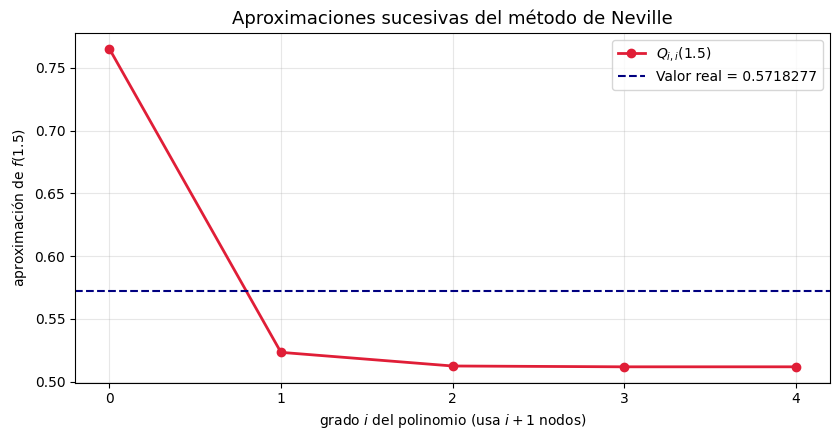

In [13]:
# 5. Gráfica
# Extraemos los valores de la diagonal principal Q_{i,i}(x) para cada grado i
grados = np.arange(len(x_nodos))
aprox_diagonales = np.diag(tabla_Q)

plt.figure(figsize=(8.5, 4.5))

# Graficamos las aproximaciones sucesivas Q_{i,i}(x)
plt.plot(grados, aprox_diagonales, marker="o", color="#e01e37", linewidth=2,
         markersize=6, label=f"$Q_{{i,i}}({x_eval})$")

# Línea horizontal con el valor de referencia
plt.axhline(valor_real, color="#000080", linestyle="--", linewidth=1.5,
            label=f"Valor real = {valor_real}")

plt.title("Aproximaciones sucesivas del método de Neville", fontsize=13)
plt.xlabel("grado $i$ del polinomio (usa $i + 1$ nodos)", fontsize=10)
plt.ylabel(f"aproximación de $f({x_eval})$", fontsize=10)
plt.xticks(grados)
plt.legend(loc="upper right")
plt.grid(True, linestyle="-", alpha=0.3)

plt.tight_layout()
plt.show()

## Conclusión y Solución Final

**Solución final:** Al aplicar el **Método de Neville** para los nodos dados y evaluar en $x = 1.5$, la aproximación de mayor grado obtenida en la esquina inferior derecha de la tabla es:
$$Q_{4,4}(1.5) \approx \mathbf{0.5118200}$$

En el ejemplo hecho en clase revisamos las aproximaciones intermedias (como $Q_{3,3} \approx 0.5118127$, $Q_{4,3} \approx 0.5118303$ y $Q_{4,4} \approx 0.5118200$) y la diferencia frente al valor real reportado en el apunte ($0.5718277$).